In [1]:


import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import (EarlyStopping,ModelCheckpoint)
from tensorflow.keras.utils import (load_img,img_to_array)
from sklearn.metrics import (confusion_matrix,classification_report,ConfusionMatrixDisplay)
print("All libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)


All libraries imported successfully!
TensorFlow Version: 2.21.0


In [2]:
DESKTOP = Path.home() / "Desktop"

PROJECT_PATH = DESKTOP / "Fruit_Freshness_Detector"



DATASET_PATH = PROJECT_PATH / "Dataset"

TRAIN_PATH = DATASET_PATH / "train"

TEST_PATH = DATASET_PATH / "test"



MODEL_PATH = PROJECT_PATH / "saved_model"

RESULTS_PATH = PROJECT_PATH / "results"

MODEL_PATH.mkdir(parents=True, exist_ok=True)

RESULTS_PATH.mkdir(parents=True, exist_ok=True)

print("\nProject Folder:", PROJECT_PATH)

print("Dataset Folder:", DATASET_PATH)

print("Training Folder:", TRAIN_PATH)

print("Testing Folder:", TEST_PATH)



Project Folder: C:\Users\Vaishnavi\Desktop\Fruit_Freshness_Detector
Dataset Folder: C:\Users\Vaishnavi\Desktop\Fruit_Freshness_Detector\Dataset
Training Folder: C:\Users\Vaishnavi\Desktop\Fruit_Freshness_Detector\Dataset\train
Testing Folder: C:\Users\Vaishnavi\Desktop\Fruit_Freshness_Detector\Dataset\test


In [3]:
if not PROJECT_PATH.exists():
    raise FileNotFoundError(
        "Project folder not found on Desktop. "
        "Check the folder name."
    )

if not DATASET_PATH.exists():
    raise FileNotFoundError(
        "Dataset folder not found. "
        "Check whether its name is Dataset."
    )

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        "Training folder not found. "
        "Dataset must contain a train folder."
    )

if not TEST_PATH.exists():
    raise FileNotFoundError(
        "Testing folder not found. "
        "Dataset must contain a test folder."
    )

print("\nDataset folders found successfully!")



Dataset folders found successfully!


In [4]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".gif")
def count_images(folder):

    image_counts = {}

    for class_folder in folder.iterdir():

        if class_folder.is_dir():

            count = 0

            for image in class_folder.rglob("*"):

                if image.is_file() and image.suffix.lower() in image_extensions:
                    count += 1

            image_counts[class_folder.name] = count

    return image_counts
train_counts = count_images(TRAIN_PATH)
test_counts = count_images(TEST_PATH)
print("Training Images:")
print(train_counts)
print("\nTesting Images:")
print(test_counts)
total_train = sum(train_counts.values())
total_test = sum(test_counts.values())
print("\nTotal Training Images:", total_train)
print("Total Testing Images:", total_test)
print("Total Dataset Images:", total_train + total_test)
count_table = pd.DataFrame({
    "Training Images": pd.Series(train_counts),
    "Testing Images": pd.Series(test_counts)})
count_table.loc["TOTAL"] = count_table.sum()
print("\nDataset Summary:")
display(count_table)

Training Images:
{'freshapples': 1693, 'freshbanana': 1581, 'freshoranges': 1466, 'rottenapples': 2342, 'rottenbanana': 2224, 'rottenoranges': 1595}

Testing Images:
{'freshapples': 395, 'freshbanana': 381, 'freshoranges': 388, 'rottenapples': 601, 'rottenbanana': 530, 'rottenoranges': 403}

Total Training Images: 10901
Total Testing Images: 2698
Total Dataset Images: 13599

Dataset Summary:


,Training Images,Testing Images
freshapples,1693,395
freshbanana,1581,381
freshoranges,1466,388
rottenapples,2342,601
rottenbanana,2224,530
rottenoranges,1595,403
TOTAL,10901,2698


In [5]:
count_table = pd.DataFrame({
 "Training Images": pd.Series(train_counts),
 "Testing Images": pd.Series(test_counts)})
count_table.loc["TOTAL"] = count_table.sum()
print("\nDataset Summary:")
print(count_table)
count_table.to_csv(RESULTS_PATH / "dataset_summary.csv")



Dataset Summary:
               Training Images  Testing Images
freshapples               1693             395
freshbanana               1581             381
freshoranges              1466             388
rottenapples              2342             601
rottenbanana              2224             530
rottenoranges             1595             403
TOTAL                    10901            2698


In [6]:
expected_classes = {
    "freshapples",
    "freshbanana",
    "freshoranges",
    "rottenapples",
    "rottenbanana",
    "rottenoranges"
}
if set(train_counts.keys()) != expected_classes:
  raise ValueError(
        "Training folder must contain these six class folders: " + str(expected_classes) )
if set(test_counts.keys()) != expected_classes:
 raise ValueError(
        "Testing folder must contain these six class folders: "+ str(expected_classes) )
print("\nAll six fruit categories are available!")



All six fruit categories are available!


In [7]:
IMAGE_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42
print("\nImage Size:", IMAGE_SIZE)
print("Batch Size:", BATCH_SIZE)


Image Size: (180, 180)
Batch Size: 32


In [8]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
TRAIN_PATH,
validation_split=0.20,
subset="training",
seed=SEED,
image_size=IMAGE_SIZE,
batch_size=BATCH_SIZE)


Found 10901 files belonging to 6 classes.
Using 8721 files for training.


In [9]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
TRAIN_PATH,
validation_split=0.20,
subset="validation",
seed=SEED,
image_size=IMAGE_SIZE,
batch_size=BATCH_SIZE)
test_dataset = tf.keras.utils.image_dataset_from_directory(
TEST_PATH,
image_size=IMAGE_SIZE,
batch_size=BATCH_SIZE,
shuffle=False
)


Found 10901 files belonging to 6 classes.
Using 2180 files for validation.
Found 2698 files belonging to 6 classes.


Fruit Categories:
['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Number of Classes: 6


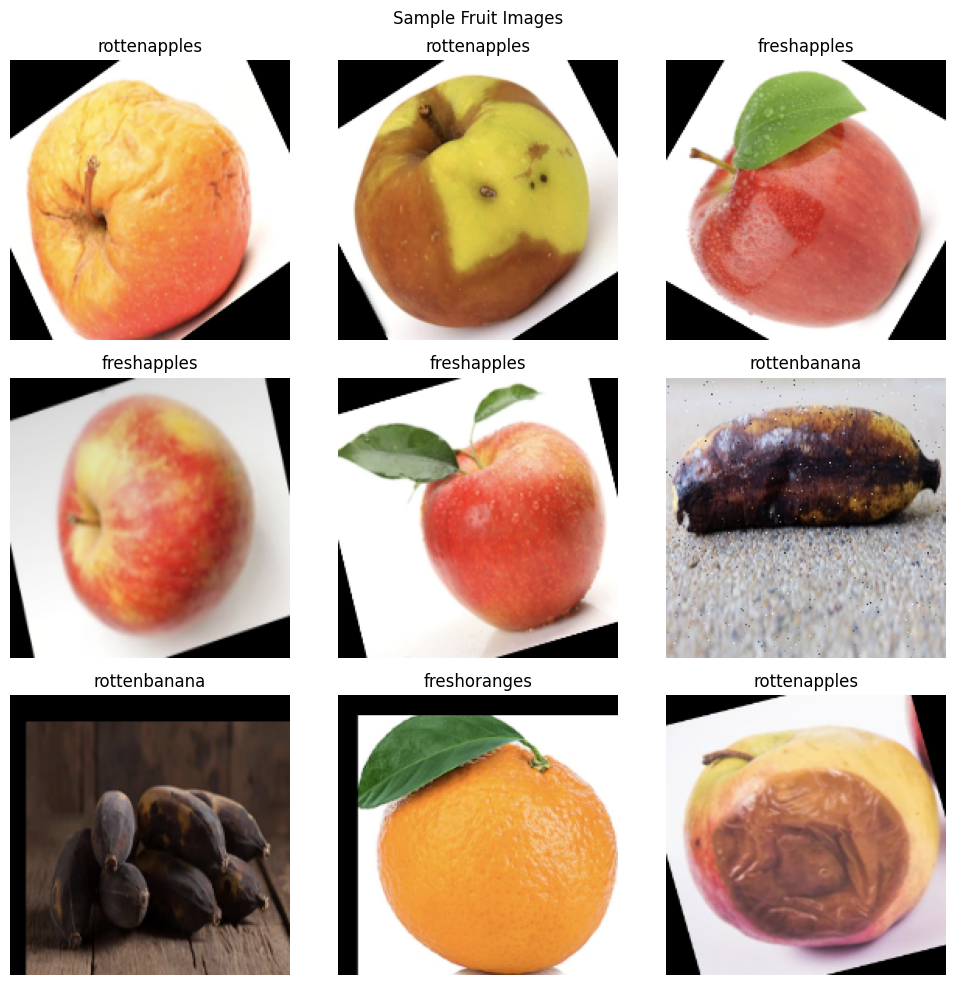

In [13]:
class_names = train_dataset.class_names
print("Fruit Categories:")
print(class_names)
print("Number of Classes:", len(class_names))
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):

    for i in range(min(9, len(images))):

        plt.subplot(3, 3, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(
            class_names[int(labels[i].numpy())]
        )

        plt.axis("off")

plt.suptitle("Sample Fruit Images")

plt.tight_layout()

plt.savefig(RESULTS_PATH / "sample_images.png")

plt.show()

In [14]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.10)])
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

In [15]:
number_of_classes = len(class_names)
model = models.Sequential([layers.Input(shape=(180, 180, 3)),
    data_augmentation,
    layers.Rescaling(1.0 / 255),
    layers.Conv2D( 32,(3, 3),  activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128,(3, 3),activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(number_of_classes, activation="softmax")])
print("\nCNN MODEL SUMMARY:")
model.summary()



CNN MODEL SUMMARY:


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 180, 180, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 180, 180, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 178, 178, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 89, 89, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 87, 87, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 43, 43, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 41, 41, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 20, 20, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 6)                   │             774 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,534 (431.77 KB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
print("\nModel compiled successfully!")


Model compiled successfully!


In [17]:
early_stopping = EarlyStopping(
 monitor="val_loss", patience=4,restore_best_weights=True)
model_checkpoint = ModelCheckpoint(filepath=str(MODEL_PATH / "best_fruit_model.keras"),
monitor="val_loss",save_best_only=True)
EPOCHS = 10
print("\nStarting CNN Model Training...")
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[
        early_stopping,
        model_checkpoint])
print("\nModel Training Completed!")


Starting CNN Model Training...
Epoch 1/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 84s 300ms/step - accuracy: 0.4951 - loss: 1.2701 - val_accuracy: 0.6780 - val_loss: 0.8504
Epoch 2/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 81s 297ms/step - accuracy: 0.7323 - loss: 0.7495 - val_accuracy: 0.8147 - val_loss: 0.5653
Epoch 3/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 86s 316ms/step - accuracy: 0.7896 - loss: 0.6024 - val_accuracy: 0.8482 - val_loss: 0.4437
Epoch 4/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 85s 312ms/step - accuracy: 0.8200 - loss: 0.5157 - val_accuracy: 0.8564 - val_loss: 0.3932
Epoch 5/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 83s 302ms/step - accuracy: 0.8335 - loss: 0.4682 - val_accuracy: 0.8743 - val_loss: 0.3449
Epoch 6/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 83s 302ms/step - accuracy: 0.8454 - loss: 0.4371 - val_accuracy: 0.8972 - val_loss: 0.3015
Epoch 7/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 82s 300ms/step - accuracy: 0.8529 - loss: 0.4050 - val_accuracy: 0.8908 - val_loss: 0.3132
Epoch 8/10
273/273 ━━━━━━━━━━━━━━━━━━━━ 82s 300ms/s

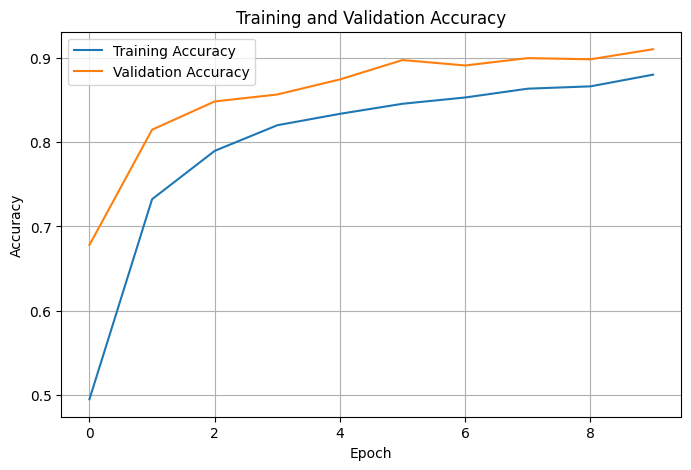

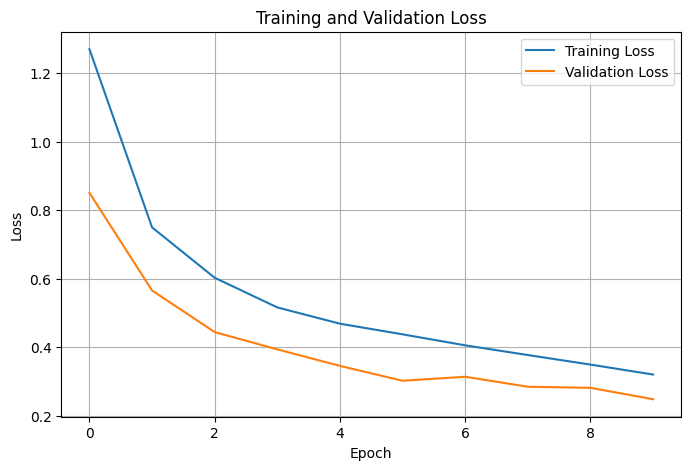

In [18]:
plt.figure(figsize=(8, 5))
plt.plot( history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.savefig(RESULTS_PATH / "accuracy_graph.png")
plt.show()

plt.figure(figsize=(8, 5))
plt.plot( history.history["loss"], label="Training Loss")
plt.plot( history.history["val_loss"],label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.savefig(RESULTS_PATH / "loss_graph.png")
plt.show()


In [19]:
test_loss, test_accuracy = model.evaluate(test_dataset)
print("\nFINAL MODEL PERFORMANCE")
print("Test Loss:", test_loss)
print("Test Accuracy:",round(test_accuracy * 100, 2),"%")

85/85 ━━━━━━━━━━━━━━━━━━━━ 7s 81ms/step - accuracy: 0.9088 - loss: 0.2483

FINAL MODEL PERFORMANCE
Test Loss: 0.248319610953331
Test Accuracy: 90.88 %


In [20]:
y_true = []
y_pred = []
for images, labels in test_dataset:
    predictions = model.predict(images,verbose=0)
    predicted_labels = np.argmax(predictions,axis=1)
    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)
y_true = np.array(y_true)
y_pred = np.array(y_pred)
print("\nAll test predictions completed!")



All test predictions completed!


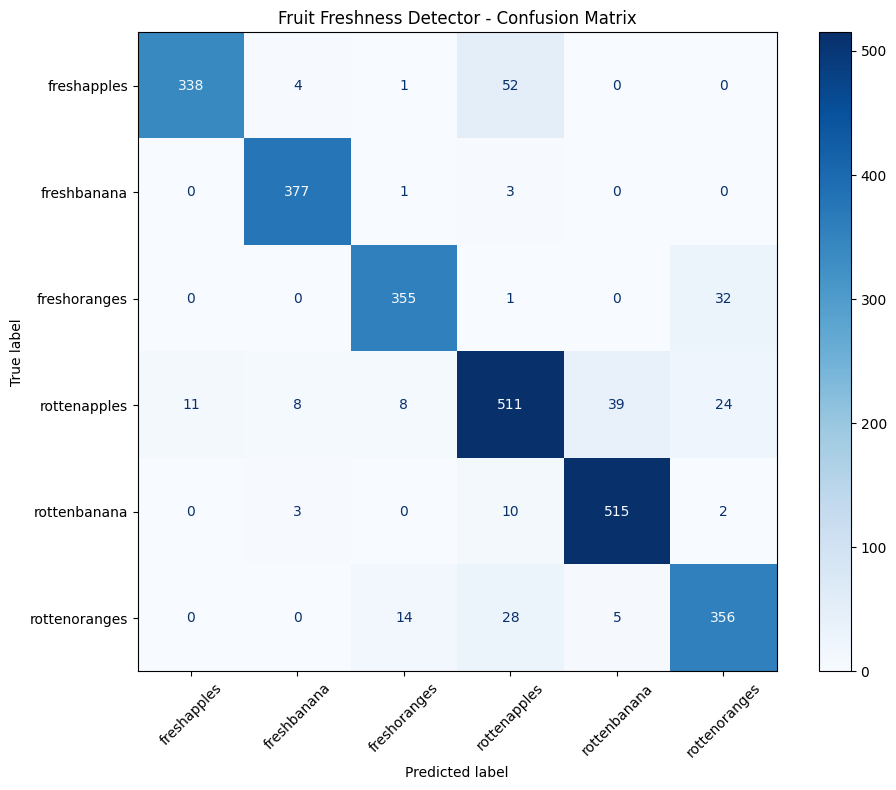

In [21]:
cm = confusion_matrix( y_true,y_pred,labels=np.arange(number_of_classes))
cm_display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(10, 8))
cm_display.plot(cmap="Blues", xticks_rotation=45,ax=ax)
plt.title("Fruit Freshness Detector - Confusion Matrix")
plt.tight_layout()
plt.savefig(RESULTS_PATH / "confusion_matrix.png")
plt.show()


In [22]:
report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(number_of_classes),
    target_names=class_names,
    zero_division=0)
print("\nCLASSIFICATION REPORT")
print(report)

with open(RESULTS_PATH / "classification_report.txt", "w") as file:
   file.write(report)



CLASSIFICATION REPORT
               precision    recall  f1-score   support

  freshapples       0.97      0.86      0.91       395
  freshbanana       0.96      0.99      0.98       381
 freshoranges       0.94      0.91      0.93       388
 rottenapples       0.84      0.85      0.85       601
 rottenbanana       0.92      0.97      0.95       530
rottenoranges       0.86      0.88      0.87       403

     accuracy                           0.91      2698
    macro avg       0.92      0.91      0.91      2698
 weighted avg       0.91      0.91      0.91      2698



In [26]:
class_names = [
    "freshapples",
    "freshbanana",
    "freshoranges",
    "rottenapples",
    "rottenbanana",
    "rottenoranges"
]
print("Fruit Categories:")
print(class_names)
print("Total Classes:", len(class_names))

Fruit Categories:
['freshapples', 'freshbanana', 'freshoranges', 'rottenapples', 'rottenbanana', 'rottenoranges']
Total Classes: 6



NEW FRUIT PREDICTION
-------------------------
Predicted Category: rottenbanana
Confidence: 50.03 %


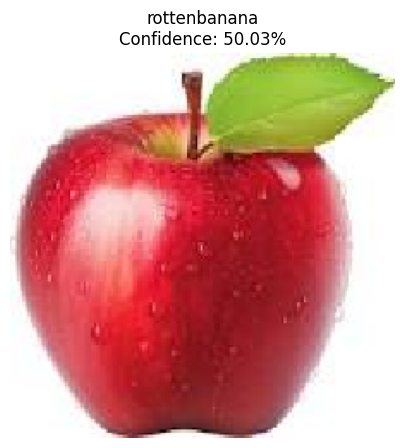

In [30]:
NEW_IMAGE_PATH = Path.home() / "Desktop" / "new_fruit.jpg"
IMAGE_SIZE = (224, 224)
if NEW_IMAGE_PATH.exists():
img = load_img( NEW_IMAGE_PATH,target_size=IMAGE_SIZE)

    img_array = img_to_array(img)
    img_array = img_array / 255.0
    img_array = np.expand_dims(img_array, axis=0)
predictions = model.predict(img_array, verbose=0)
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]
confidence = predictions[0][predicted_index] * 100
    print("\nNEW FRUIT PREDICTION")
    print("-------------------------")
    print("Predicted Category:", predicted_class)
    print("Confidence:", round(float(confidence), 2), "%")
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title( f"{predicted_class}\nConfidence: {confidence:.2f}%")
    plt.axis("off")
    plt.show()
else:
    print("No new fruit image found.")
    print("Add new_fruit.jpg to your Desktop.")

In [28]:
model.save( MODEL_PATH / "fruit_freshness_detector.keras")
print("\nFinal model saved successfully!")
results = pd.DataFrame({"Metric": [ "Test Accuracy","Test Loss"],"Value": [test_accuracy,test_loss]})
results.to_csv(RESULTS_PATH / "model_results.csv",index=False)
print("\nMODEL RESULTS")
print(results)


history_df = pd.DataFrame(history.history)
history_df.to_csv(RESULTS_PATH / "training_history.csv",index=False)



Final model saved successfully!

MODEL RESULTS
          Metric     Value
0  Test Accuracy  0.908821
1      Test Loss  0.248320
